In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import csv
import sys

def read_csv(file_path):

    csv.field_size_limit(sys.maxsize)

    data = []

    with open(file_path, 'r', encoding='utf-8') as file:

        csv_reader = csv.reader(file)

        for row in csv_reader:
            data.append(row)

    return data[:60]

In [ ]:
read_csv("/content/drive/MyDrive/ml-latest-small/links.csv")

[['movieId', 'imdbId', 'tmdbId'],
 ['1', '0114709', '862'],
 ['2', '0113497', '8844'],
 ['3', '0113228', '15602'],
 ['4', '0114885', '31357'],
 ['5', '0113041', '11862'],
 ['6', '0113277', '949'],
 ['7', '0114319', '11860'],
 ['8', '0112302', '45325'],
 ['9', '0114576', '9091']]

In [ ]:
read_csv("/content/drive/MyDrive/ml-latest-small/movies.csv")

[['movieId', 'title', 'genres'],
 ['1', 'Toy Story (1995)', 'Adventure|Animation|Children|Comedy|Fantasy'],
 ['2', 'Jumanji (1995)', 'Adventure|Children|Fantasy'],
 ['3', 'Grumpier Old Men (1995)', 'Comedy|Romance'],
 ['4', 'Waiting to Exhale (1995)', 'Comedy|Drama|Romance'],
 ['5', 'Father of the Bride Part II (1995)', 'Comedy'],
 ['6', 'Heat (1995)', 'Action|Crime|Thriller'],
 ['7', 'Sabrina (1995)', 'Comedy|Romance'],
 ['8', 'Tom and Huck (1995)', 'Adventure|Children'],
 ['9', 'Sudden Death (1995)', 'Action'],
 ['10', 'GoldenEye (1995)', 'Action|Adventure|Thriller'],
 ['11', 'American President, The (1995)', 'Comedy|Drama|Romance'],
 ['12', 'Dracula: Dead and Loving It (1995)', 'Comedy|Horror'],
 ['13', 'Balto (1995)', 'Adventure|Animation|Children'],
 ['14', 'Nixon (1995)', 'Drama'],
 ['15', 'Cutthroat Island (1995)', 'Action|Adventure|Romance'],
 ['16', 'Casino (1995)', 'Crime|Drama'],
 ['17', 'Sense and Sensibility (1995)', 'Drama|Romance'],
 ['18', 'Four Rooms (1995)', 'Comedy']

In [ ]:
read_csv("/content/drive/MyDrive/ml-latest-small/ratings.csv")

[['userId', 'movieId', 'rating', 'timestamp'],
 ['1', '1', '4.0', '964982703'],
 ['1', '3', '4.0', '964981247'],
 ['1', '6', '4.0', '964982224'],
 ['1', '47', '5.0', '964983815'],
 ['1', '50', '5.0', '964982931'],
 ['1', '70', '3.0', '964982400'],
 ['1', '101', '5.0', '964980868'],
 ['1', '110', '4.0', '964982176'],
 ['1', '151', '5.0', '964984041']]

In [ ]:
read_csv("/content/drive/MyDrive/ml-latest-small/tags.csv")

[['userId', 'movieId', 'tag', 'timestamp'],
 ['2', '60756', 'funny', '1445714994'],
 ['2', '60756', 'Highly quotable', '1445714996'],
 ['2', '60756', 'will ferrell', '1445714992'],
 ['2', '89774', 'Boxing story', '1445715207'],
 ['2', '89774', 'MMA', '1445715200'],
 ['2', '89774', 'Tom Hardy', '1445715205'],
 ['2', '106782', 'drugs', '1445715054'],
 ['2', '106782', 'Leonardo DiCaprio', '1445715051'],
 ['2', '106782', 'Martin Scorsese', '1445715056']]

In [ ]:
movies_file = '/content/drive/MyDrive/ml-latest-small/movies.csv'
ratings_file = '/content/drive/MyDrive/ml-latest-small/ratings.csv'
tags_file = '/content/drive/MyDrive/ml-latest-small/tags.csv'

In [ ]:
user_to_index = {}
index_to_user = []

item_to_index = {}
index_to_item = []

data_by_user = []
data_by_item = []


In [ ]:
with open(ratings_file, "r", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        u = row["userId"]
        if u not in user_to_index:
            user_to_index[u] = len(index_to_user)
            index_to_user.append(u)

# Films : tout le catalogue de movies.csv
with open(movies_file, "r", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        m = row["movieId"]
        if m not in item_to_index:
            item_to_index[m] = len(index_to_item)
            index_to_item.append(m)

In [ ]:
print(user_to_index)

{'1': 0, '2': 1, '3': 2, '4': 3, '5': 4, '6': 5, '7': 6, '8': 7, '9': 8, '10': 9, '11': 10, '12': 11, '13': 12, '14': 13, '15': 14, '16': 15, '17': 16, '18': 17, '19': 18, '20': 19, '21': 20, '22': 21, '23': 22, '24': 23, '25': 24, '26': 25, '27': 26, '28': 27, '29': 28, '30': 29, '31': 30, '32': 31, '33': 32, '34': 33, '35': 34, '36': 35, '37': 36, '38': 37, '39': 38, '40': 39, '41': 40, '42': 41, '43': 42, '44': 43, '45': 44, '46': 45, '47': 46, '48': 47, '49': 48, '50': 49, '51': 50, '52': 51, '53': 52, '54': 53, '55': 54, '56': 55, '57': 56, '58': 57, '59': 58, '60': 59, '61': 60, '62': 61, '63': 62, '64': 63, '65': 64, '66': 65, '67': 66, '68': 67, '69': 68, '70': 69, '71': 70, '72': 71, '73': 72, '74': 73, '75': 74, '76': 75, '77': 76, '78': 77, '79': 78, '80': 79, '81': 80, '82': 81, '83': 82, '84': 83, '85': 84, '86': 85, '87': 86, '88': 87, '89': 88, '90': 89, '91': 90, '92': 91, '93': 92, '94': 93, '95': 94, '96': 95, '97': 96, '98': 97, '99': 98, '100': 99, '101': 100, '102'

In [ ]:
print(index_to_user)

['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '96', '97', '98', '99', '100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '110', '111', '112', '113', '114', '115', '116', '117', '118', '119', '120', '121', '122', '123', '124', '125', '126', '127', '128', '129', '130', '131', '132', '133', '134', '135', '136', '137', '138', '139', '140', '141', '142', '143', '144', '145', '146', '147', '148', '149', '150', '151', '152', '153', '154', '155', '156', '157', '158', '

In [ ]:
print(item_to_index)

{'1': 0, '2': 1, '3': 2, '4': 3, '5': 4, '6': 5, '7': 6, '8': 7, '9': 8, '10': 9, '11': 10, '12': 11, '13': 12, '14': 13, '15': 14, '16': 15, '17': 16, '18': 17, '19': 18, '20': 19, '21': 20, '22': 21, '23': 22, '24': 23, '25': 24, '26': 25, '27': 26, '28': 27, '29': 28, '30': 29, '31': 30, '32': 31, '34': 32, '36': 33, '38': 34, '39': 35, '40': 36, '41': 37, '42': 38, '43': 39, '44': 40, '45': 41, '46': 42, '47': 43, '48': 44, '49': 45, '50': 46, '52': 47, '53': 48, '54': 49, '55': 50, '57': 51, '58': 52, '60': 53, '61': 54, '62': 55, '63': 56, '64': 57, '65': 58, '66': 59, '68': 60, '69': 61, '70': 62, '71': 63, '72': 64, '73': 65, '74': 66, '75': 67, '76': 68, '77': 69, '78': 70, '79': 71, '80': 72, '81': 73, '82': 74, '83': 75, '85': 76, '86': 77, '87': 78, '88': 79, '89': 80, '92': 81, '93': 82, '94': 83, '95': 84, '96': 85, '97': 86, '99': 87, '100': 88, '101': 89, '102': 90, '103': 91, '104': 92, '105': 93, '106': 94, '107': 95, '108': 96, '110': 97, '111': 98, '112': 99, '113':

In [ ]:
print(index_to_item)

['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '34', '36', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '52', '53', '54', '55', '57', '58', '60', '61', '62', '63', '64', '65', '66', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '85', '86', '87', '88', '89', '92', '93', '94', '95', '96', '97', '99', '100', '101', '102', '103', '104', '105', '106', '107', '108', '110', '111', '112', '113', '116', '117', '118', '119', '121', '122', '123', '125', '126', '128', '129', '132', '135', '137', '140', '141', '144', '145', '146', '147', '148', '149', '150', '151', '152', '153', '154', '155', '156', '157', '158', '159', '160', '161', '162', '163', '164', '165', '166', '168', '169', '170', '171', '172', '173', '174', '175', '176', '177', '178', '179', '180', '181', '183', '184', '185

In [ ]:
read_csv("/content/drive/MyDrive/ml-latest-small/ratings.csv")

[['userId', 'movieId', 'rating', 'timestamp'],
 ['1', '1', '4.0', '964982703'],
 ['1', '3', '4.0', '964981247'],
 ['1', '6', '4.0', '964982224'],
 ['1', '47', '5.0', '964983815'],
 ['1', '50', '5.0', '964982931'],
 ['1', '70', '3.0', '964982400'],
 ['1', '101', '5.0', '964980868'],
 ['1', '110', '4.0', '964982176'],
 ['1', '151', '5.0', '964984041'],
 ['1', '157', '5.0', '964984100'],
 ['1', '163', '5.0', '964983650'],
 ['1', '216', '5.0', '964981208'],
 ['1', '223', '3.0', '964980985'],
 ['1', '231', '5.0', '964981179'],
 ['1', '235', '4.0', '964980908'],
 ['1', '260', '5.0', '964981680'],
 ['1', '296', '3.0', '964982967'],
 ['1', '316', '3.0', '964982310'],
 ['1', '333', '5.0', '964981179'],
 ['1', '349', '4.0', '964982563'],
 ['1', '356', '4.0', '964980962'],
 ['1', '362', '5.0', '964982588'],
 ['1', '367', '4.0', '964981710'],
 ['1', '423', '3.0', '964982363'],
 ['1', '441', '4.0', '964980868'],
 ['1', '457', '5.0', '964981909'],
 ['1', '480', '4.0', '964982346'],
 ['1', '500', '3.

In [ ]:
print(len(ratings_file))

50


In [ ]:
with open(ratings_file, "r", encoding="utf-8") as f:
  reader = csv.DictReader(f)
  count = 0
  userId = 0
  for row in reader:
    if userId != int(row["userId"]):
      count +=1
    userId = int(row["userId"])


In [ ]:
 print(count)

610


In [ ]:

def build_data(file_path):
    
    data_by_user = [[] for _ in range(len(index_to_user))]
    data_by_item = [[] for _ in range(len(index_to_item))]
    with open(file_path, "r", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            u = user_to_index[row["userId"]]
            i = item_to_index[row["movieId"]]
            r = float(row["rating"])              # converti une seule fois
            data_by_user[u].append((i, r))
            data_by_item[i].append((u, r))
    return data_by_user, data_by_item


data_by_user, data_by_item = build_data(ratings_file)

In [ ]:
print(data_by_user)

[[(0, 4.0), (2, 4.0), (5, 4.0), (43, 5.0), (46, 5.0), (62, 3.0), (89, 5.0), (97, 4.0), (124, 5.0), (130, 5.0), (136, 5.0), (184, 5.0), (190, 3.0), (197, 5.0), (201, 4.0), (224, 5.0), (257, 3.0), (275, 3.0), (291, 5.0), (307, 4.0), (314, 4.0), (320, 5.0), (325, 4.0), (367, 3.0), (384, 4.0), (398, 5.0), (418, 4.0), (436, 3.0), (461, 5.0), (476, 4.0), (484, 4.0), (485, 5.0), (508, 4.0), (509, 4.0), (510, 4.0), (513, 5.0), (520, 5.0), (546, 3.0), (551, 5.0), (559, 3.0), (592, 4.0), (594, 3.0), (615, 3.0), (632, 4.0), (701, 5.0), (705, 5.0), (720, 5.0), (723, 4.0), (734, 5.0), (767, 3.0), (781, 5.0), (782, 5.0), (783, 5.0), (786, 5.0), (787, 3.0), (788, 5.0), (789, 5.0), (797, 4.0), (801, 5.0), (810, 4.0), (815, 5.0), (820, 5.0), (828, 5.0), (829, 4.0), (831, 5.0), (836, 5.0), (856, 4.0), (863, 5.0), (898, 5.0), (899, 5.0), (900, 5.0), (907, 5.0), (909, 4.0), (911, 5.0), (914, 5.0), (915, 4.0), (920, 2.0), (921, 5.0), (923, 5.0), (925, 5.0), (927, 5.0), (939, 5.0), (955, 5.0), (957, 3.0), (

In [ ]:
with open(ratings_file, "r", encoding="utf-8") as f:
  reader = list(csv.reader(f))

print(reader[-1])

['610', '170875', '3.0', '1493846415']


In [ ]:
print(index_to_item[872])

1161


In [ ]:
print(item_to_index["170875"])

9503


In [ ]:
len(user_to_index)

610

In [ ]:
len(data_by_user)

610

In [ ]:
print(item_to_index)

{'1': 0, '2': 1, '3': 2, '4': 3, '5': 4, '6': 5, '7': 6, '8': 7, '9': 8, '10': 9, '11': 10, '12': 11, '13': 12, '14': 13, '15': 14, '16': 15, '17': 16, '18': 17, '19': 18, '20': 19, '21': 20, '22': 21, '23': 22, '24': 23, '25': 24, '26': 25, '27': 26, '28': 27, '29': 28, '30': 29, '31': 30, '32': 31, '34': 32, '36': 33, '38': 34, '39': 35, '40': 36, '41': 37, '42': 38, '43': 39, '44': 40, '45': 41, '46': 42, '47': 43, '48': 44, '49': 45, '50': 46, '52': 47, '53': 48, '54': 49, '55': 50, '57': 51, '58': 52, '60': 53, '61': 54, '62': 55, '63': 56, '64': 57, '65': 58, '66': 59, '68': 60, '69': 61, '70': 62, '71': 63, '72': 64, '73': 65, '74': 66, '75': 67, '76': 68, '77': 69, '78': 70, '79': 71, '80': 72, '81': 73, '82': 74, '83': 75, '85': 76, '86': 77, '87': 78, '88': 79, '89': 80, '92': 81, '93': 82, '94': 83, '95': 84, '96': 85, '97': 86, '99': 87, '100': 88, '101': 89, '102': 90, '103': 91, '104': 92, '105': 93, '106': 94, '107': 95, '108': 96, '110': 97, '111': 98, '112': 99, '113':

In [ ]:
data_by_item = []

In [ ]:
# for _ in range(len(index_to_item)):
#   data_by_item.append([])

# with open(ratings_file, "r", encoding="utf-8") as f:
#   reader = csv.DictReader(f)

#   for row in reader:
#     item_index = item_to_index[row["movieId"]]
#     user_index = user_to_index[row["userId"]]
#     rating = row["rating"]

#     data_by_item[item_index].append([user_index, rating])

In [ ]:
print(data_by_item)

[[(0, 4.0), (4, 4.0), (6, 4.5), (14, 2.5), (16, 4.5), (17, 3.5), (18, 4.0), (20, 3.5), (26, 3.0), (30, 5.0), (31, 3.0), (32, 3.0), (39, 5.0), (42, 5.0), (43, 3.0), (44, 4.0), (45, 5.0), (49, 3.0), (53, 3.0), (56, 5.0), (62, 5.0), (63, 4.0), (65, 4.0), (67, 2.5), (70, 5.0), (72, 4.5), (75, 0.5), (77, 4.0), (81, 2.5), (85, 4.0), (88, 3.0), (89, 3.0), (90, 4.0), (92, 3.0), (95, 5.0), (97, 4.5), (102, 4.0), (106, 4.0), (111, 3.0), (118, 3.5), (120, 4.0), (123, 4.0), (129, 3.0), (131, 2.0), (133, 3.0), (134, 4.0), (136, 4.0), (139, 3.0), (140, 4.0), (143, 3.5), (144, 5.0), (150, 5.0), (152, 2.0), (154, 3.0), (155, 4.0), (158, 4.5), (159, 4.0), (160, 4.0), (165, 5.0), (166, 3.5), (168, 4.5), (170, 5.0), (176, 5.0), (177, 4.0), (178, 4.0), (181, 4.0), (184, 4.0), (185, 4.0), (190, 4.0), (192, 2.0), (199, 3.5), (200, 5.0), (201, 4.0), (205, 5.0), (212, 3.5), (213, 3.0), (215, 3.0), (216, 4.0), (218, 3.5), (219, 5.0), (222, 3.5), (225, 3.5), (228, 5.0), (231, 3.5), (232, 3.0), (233, 5.0), (238,

In [ ]:
trois = data_by_item[0][:3]          # [[0, '4.0'], [4, '4.0'], [6, '4.5']]

movie_id = index_to_item[0]
user_ids = {index_to_user[u] for u, r in trois}

with open(ratings_file, "r", encoding="utf-8") as f:
    reader = csv.reader(f)
    print(next(reader))
    for row in reader:
        if row[1] == movie_id and row[0] in user_ids:
            print(row)

['userId', 'movieId', 'rating', 'timestamp']
['1', '1', '4.0', '964982703']
['5', '1', '4.0', '847434962']
['7', '1', '4.5', '1106635946']


In [ ]:
with open(ratings_file, "r", encoding="utf-8") as f:
  reader = list(csv.reader(f))

print(reader[-1])

['610', '170875', '3.0', '1493846415']


In [ ]:
print(index_to_user[609])

610


In [ ]:
print(item_to_index["170875"])

9503


In [ ]:
len(user_to_index)

610

In [ ]:
len(data_by_item)

9742

## PLot the data

Users : n=610, min=20, max=2698, moyenne=165.3, médiane=70


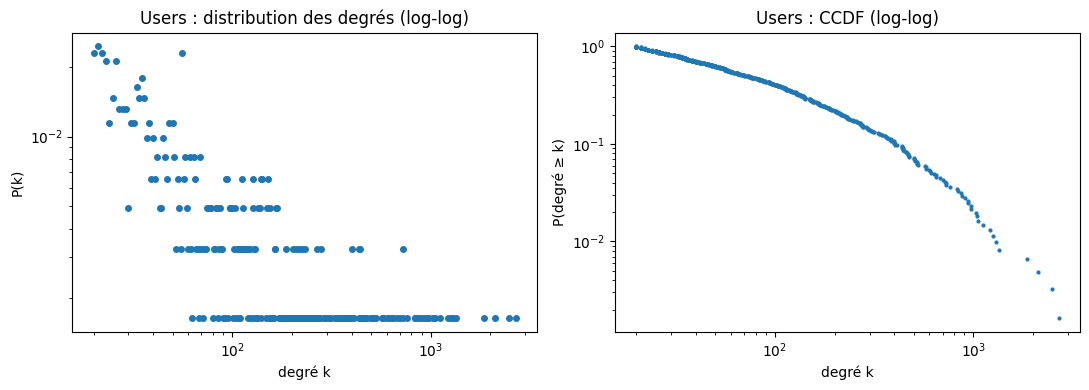

Films : n=9724, min=1, max=329, moyenne=10.4, médiane=3


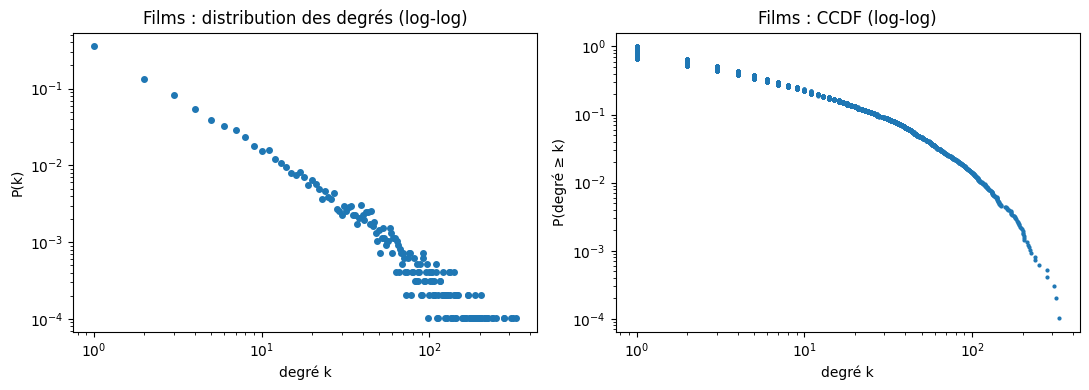

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

user_degrees = [len(l) for l in data_by_user]
item_degrees = [len(l) for l in data_by_item]

def plot_degrees(degrees, name):
    degrees = np.array([d for d in degrees if d > 0])   # log(0) impossible
    n = len(degrees)

    # distribution : proportion de noeuds pour chaque degré
    counts = Counter(degrees)
    x = np.array(sorted(counts))
    p = np.array([counts[k] for k in x]) / n

    # CCDF : proportion de noeuds de degré >= k
    d_sorted = np.sort(degrees)
    ccdf = 1 - np.arange(n) / n

    print(f"{name} : n={n}, min={degrees.min()}, max={degrees.max()}, "
          f"moyenne={degrees.mean():.1f}, médiane={np.median(degrees):.0f}")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].loglog(x, p, "o", markersize=4)
    axes[0].set_title(f"{name} : distribution des degrés (log-log)")
    axes[0].set_xlabel("degré k")
    axes[0].set_ylabel("P(k)")

    axes[1].loglog(d_sorted, ccdf, ".", markersize=4)
    axes[1].set_title(f"{name} : CCDF (log-log)")
    axes[1].set_xlabel("degré k")
    axes[1].set_ylabel("P(degré ≥ k)")

    plt.tight_layout()
    plt.show()

plot_degrees(user_degrees, "Users")
plot_degrees(item_degrees, "Films")

In [ ]:
!pip install powerlaw
import powerlaw

for name, deg in [("Users", user_degrees), ("Films", item_degrees)]:
    deg = [d for d in deg if d > 0]
    fit = powerlaw.Fit(deg, discrete=True)
    print(name, "| alpha =", round(fit.power_law.alpha, 2), "| xmin =", fit.power_law.xmin)
    R, p = fit.distribution_compare("power_law", "lognormal")
    print("   power_law vs lognormal : R =", round(R, 2), ", p =", round(p, 3))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.0/192.0 kB 10.8 MB/s eta 0:00:00
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 259/259 [00:00<00:00, 1699.46it/s]


Users | alpha = 2.07 | xmin = 93.0
   power_law vs lognormal : R = -10.1 , p = 0.005
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 175/175 [00:00<00:00, 330.45it/s]


Films | alpha = 2.79 | xmin = 39.0
   power_law vs lognormal : R = -15.45 , p = 0.0


## SPlit the data

In [ ]:
import os, random

random.seed(42)

rows_by_user = {}
with open(ratings_file, "r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    fieldnames = reader.fieldnames
    for row in reader:
        rows_by_user.setdefault(row["userId"], []).append(row)

folder = os.path.dirname(ratings_file)
train_file = os.path.join(folder, "train_ratings_90.csv")
test_file  = os.path.join(folder, "test_ratings_10.csv")

with open(train_file, "w", encoding="utf-8", newline="") as ftrain, \
     open(test_file, "w", encoding="utf-8", newline="") as ftest:

    train_writer = csv.DictWriter(ftrain, fieldnames=fieldnames)
    test_writer  = csv.DictWriter(ftest, fieldnames=fieldnames)
    train_writer.writeheader()
    test_writer.writeheader()

    for user_id, rows in rows_by_user.items():
        random.shuffle(rows)
        cut = int(0.9 * len(rows))
        train_writer.writerows(rows[:cut])
        test_writer.writerows(rows[cut:])

In [ ]:
with open(train_file, "r", encoding="utf-8") as f:
    n_train = sum(1 for _ in f) - 1

with open(test_file, "r", encoding="utf-8") as f:
    n_test = sum(1 for _ in f) - 1

print("ratings train :", n_train)
print("ratings test  :", n_test)
print("total         :", n_train + n_test)

ratings train : 90478
ratings test  : 10358
total         : 100836


In [ ]:
# def build_data_by_user(file_path):
#     data_by_user = []
#     with open(file_path, "r", encoding="utf-8") as f:
#         reader = csv.DictReader(f)
#         last_index = 0
#         movie_rating = []

#         for row in reader:
#             if last_index != user_to_index[row["userId"]]:
#                 data_by_user.append(movie_rating)
#                 movie_rating = []
#             user_index = user_to_index[row["userId"]]
#             last_index = user_to_index[row["userId"]]
#             item_index = item_to_index[row["movieId"]]
#             rating = row["rating"]

#             movie_rating.append([item_index, rating])
#         data_by_user.append(movie_rating)
#     return data_by_user


# def build_data_by_item(file_path):
#     data_by_item = []
#     for _ in range(len(index_to_item)):
#         data_by_item.append([])

#     with open(file_path, "r", encoding="utf-8") as f:
#         reader = csv.DictReader(f)

#         for row in reader:
#             item_index = item_to_index[row["movieId"]]
#             user_index = user_to_index[row["userId"]]
#             rating = row["rating"]

#             data_by_item[item_index].append([user_index, rating])
#     return data_by_item

In [ ]:
def build_data(file_path):
    """Une seule lecture. Les deux listes sont alignées sur les indices,
    quel que soit l'ordre des lignes ; un utilisateur sans note a une liste vide."""
    data_by_user = [[] for _ in range(len(index_to_user))]
    data_by_item = [[] for _ in range(len(index_to_item))]
    with open(file_path, "r", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            u = user_to_index[row["userId"]]
            i = item_to_index[row["movieId"]]
            r = float(row["rating"])              # converti une seule fois
            data_by_user[u].append((i, r))
            data_by_item[i].append((u, r))
    return data_by_user, data_by_item


data_by_user_train, data_by_item_train = build_data(train_file)
data_by_user_test,  data_by_item_test  = build_data(test_file)

In [ ]:
# data_by_user_train = build_data_by_user(train_file)
# data_by_user_test  = build_data_by_user(test_file)

# data_by_item_train = build_data_by_item(train_file)
# data_by_item_test  = build_data_by_item(test_file)

In [ ]:
print(data_by_user_train)

[[(1687, 4.0), (1235, 3.0), (130, 5.0), (1617, 5.0), (783, 5.0), (1790, 2.0), (1224, 5.0), (939, 5.0), (2254, 5.0), (2394, 1.0), (1957, 5.0), (476, 4.0), (1332, 5.0), (2226, 5.0), (2103, 4.0), (2182, 5.0), (1431, 5.0), (1326, 4.0), (1526, 5.0), (1319, 4.0), (2696, 4.0), (5, 4.0), (815, 5.0), (820, 5.0), (2788, 5.0), (923, 5.0), (1503, 4.0), (964, 4.0), (2303, 5.0), (856, 4.0), (320, 5.0), (1644, 4.0), (1577, 5.0), (190, 3.0), (705, 5.0), (909, 4.0), (436, 3.0), (1796, 5.0), (1567, 4.0), (136, 5.0), (2765, 5.0), (484, 4.0), (615, 3.0), (701, 5.0), (2434, 3.0), (969, 5.0), (46, 5.0), (1516, 4.0), (1333, 4.0), (2431, 3.0), (62, 3.0), (520, 5.0), (1171, 4.0), (43, 5.0), (224, 5.0), (2193, 4.0), (1401, 4.0), (2608, 4.0), (1986, 4.0), (2157, 5.0), (1814, 3.0), (2579, 5.0), (990, 5.0), (1704, 5.0), (1691, 4.0), (921, 5.0), (925, 5.0), (723, 4.0), (1218, 5.0), (1858, 5.0), (911, 5.0), (551, 5.0), (197, 5.0), (1979, 4.0), (2636, 4.0), (831, 5.0), (1487, 4.0), (0, 4.0), (1599, 5.0), (1553, 5.0),

In [ ]:
print(data_by_user_test)

[[(2847, 4.0), (1806, 4.0), (1556, 3.0), (810, 4.0), (788, 5.0), (367, 3.0), (97, 4.0), (124, 5.0), (1298, 5.0), (1788, 5.0), (325, 4.0), (1601, 4.0), (2836, 5.0), (1987, 5.0), (418, 4.0), (2216, 5.0), (513, 5.0), (797, 4.0), (828, 5.0), (900, 5.0), (2218, 5.0), (89, 5.0), (461, 5.0), (1904, 3.0)], [(4615, 4.0), (7590, 4.0), (6253, 4.0)], [(3666, 0.5), (853, 0.5), (3734, 5.0), (5052, 4.5)], [(676, 4.0), (257, 1.0), (1640, 5.0), (3166, 2.0), (512, 3.0), (1741, 2.0), (1608, 5.0), (1445, 4.0), (2078, 4.0), (161, 2.0), (3486, 5.0), (905, 5.0), (3005, 4.0), (198, 5.0), (1791, 5.0), (2988, 3.0), (2036, 2.0), (189, 1.0), (696, 5.0), (891, 5.0), (680, 5.0), (510, 5.0)], [(277, 3.0), (337, 2.0), (520, 3.0), (461, 5.0), (275, 2.0)], [(533, 3.0), (451, 4.0), (311, 4.0), (579, 3.0), (658, 4.0), (142, 3.0), (801, 5.0), (132, 3.0), (249, 2.0), (639, 3.0), (39, 4.0), (476, 3.0), (568, 3.0), (185, 3.0), (222, 3.0), (431, 3.0), (115, 3.0), (3, 3.0), (156, 3.0), (241, 3.0), (404, 2.0), (514, 4.0), (383,

In [ ]:
print("len data_by_user_train :", len(data_by_user_train))
print("len data_by_user_test  :", len(data_by_user_test))
print("len data_by_item_train :", len(data_by_item_train))
print("len data_by_item_test  :", len(data_by_item_test))
print()
print("len index_to_user :", len(index_to_user))
print("len index_to_item :", len(index_to_item))
print()

print("data_by_user_train[0][:5] :", data_by_user_train[0][:5])
print("data_by_user_test[0][:5]  :", data_by_user_test[0][:5])
print("data_by_item_train[0][:5] :", data_by_item_train[0][:5])
print("data_by_item_test[0][:5]  :", data_by_item_test[0][:5])
print()

print("nb ratings train (user) :", sum(len(l) for l in data_by_user_train))
print("nb ratings test  (user) :", sum(len(l) for l in data_by_user_test))
print("nb ratings train (item) :", sum(len(l) for l in data_by_item_train))
print("nb ratings test  (item) :", sum(len(l) for l in data_by_item_test))

len data_by_user_train : 610
len data_by_user_test  : 610
len data_by_item_train : 9742
len data_by_item_test  : 9742

len index_to_user : 610
len index_to_item : 9742

data_by_user_train[0][:5] : [(1687, 4.0), (1235, 3.0), (130, 5.0), (1617, 5.0), (783, 5.0)]
data_by_user_test[0][:5]  : [(2847, 4.0), (1806, 4.0), (1556, 3.0), (810, 4.0), (788, 5.0)]
data_by_item_train[0][:5] : [(0, 4.0), (4, 4.0), (6, 4.5), (14, 2.5), (16, 4.5)]
data_by_item_test[0][:5]  : [(26, 3.0), (39, 5.0), (72, 4.5), (106, 4.0), (131, 2.0)]

nb ratings train (user) : 90478
nb ratings test  (user) : 10358
nb ratings train (item) : 90478
nb ratings test  (item) : 10358


In [ ]:
def same_ratings(by_user, by_item):
    a = {(u, i, r) for u, liste in enumerate(by_user) for i, r in liste}
    b = {(u, i, r) for i, liste in enumerate(by_item) for u, r in liste}
    return a == b, len(a), len(b)

print("train :", same_ratings(data_by_user_train, data_by_item_train))
print("test  :", same_ratings(data_by_user_test,  data_by_item_test))

train : (True, 90478, 90478)
test  : (True, 10358, 10358)


## Practice 2 : Compute the maximum likelihood (bias only)

### Define user_biases and item_biases

In [ ]:
# for m in range(M):
#   bias = 0
#   item_counter = 0
#   for (n, r) in data_by_user_train[m]:
#     bias += llambda * (float(r) - item_biases[n])
#     item_counter += 1

#   user_biases[m] = bias / ((llambda * item_counter) + gamma)

In [ ]:
# for n in range(N):
#   bias = 0
#   user_counter = 0
#   for m, r in data_by_item_train[n]:
#     bias += llambda * (float(r) - user_biases[m])
#     user_counter += 1
#   item_biases[n] = bias / ((llambda * user_counter) + gamma)

In [ ]:
# Loss = 0
# sse = 0
# N = 0

# for m in range (len(index_to_user)):
#   for n, r in data_by_user_train[m]:
#     err = float(r) - (user_biases[m] + item_biases[n])
#     sse += pow(err, 2)
#     N += 1

# Loss = (-(llambda/2)*sse) + ((N/2) * np.log(llambda / (2 * np.pi)))

In [ ]:
# print(Loss)

-117095.28955655353


## Plot the Negative Log-likelihood

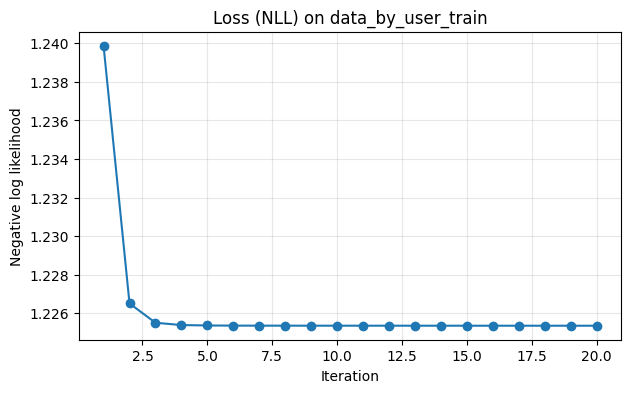

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

llambda = 1.0
gamma   = 0.1

M = len(index_to_user)
N = len(index_to_item)

user_biases = np.zeros((M))
item_biases = np.zeros((N))

n_user = len(index_to_user)
n_item = len(index_to_item)
n_iter = 20
losses = []
n_ratings = sum(len(l) for l in data_by_user_train)

def compute_NLL(n_user, data_by_user_train, user_biases, item_biases, llambda):
  sse = 0
  N = 0
  loss = 0
  nlloss = 0
  for m in range(n_user):
    for n, r in data_by_user_train[m]:
      err = float(r) - (user_biases[m] + item_biases[n])
      sse += pow(err, 2)
      N += 1

  loss = (-(llambda/2)*sse) + ((N/2) * np.log(llambda / (2 * np.pi)))
  nlloss = - loss
  return nlloss

# def compute_NLL(data_by_user, user_biases, item_biases, mu, llambda, gamma):
#     sse, N = 0.0, 0
#     for m, lst in enumerate(data_by_user):
#         for n, r in lst:
#             sse += (r - (mu + user_biases[m] + item_biases[n])) ** 2
#             N += 1
#     ll = -0.5 * llambda * sse + 0.5 * N * np.log(llambda / (2 * np.pi))
#     nb = len(user_biases) + len(item_biases)
#     lp = (-0.5 * gamma * (user_biases @ user_biases + item_biases @ item_biases)
#           + 0.5 * nb * np.log(gamma / (2 * np.pi)))
#     return -(ll + lp)


for it in range(n_iter):

  for m in range(n_user):
    bias_1 = 0
    item_counter = 0

    for n, r in data_by_user_train[m]:
      bias_1 += llambda * (float(r) - item_biases[n])
      item_counter += 1
    if item_counter > 0:
      user_biases[m] = bias_1 / ((llambda * item_counter) + gamma)

  for n in range(n_item):
    bias_2 = 0
    user_counter = 0

    for m, r in data_by_item_train[n]:
      bias_2 += llambda * (float(r) - user_biases[m])
      user_counter += 1
    if user_counter > 0:
      item_biases[n] = bias_2 / ((llambda * user_counter) + gamma)

  losses.append(compute_NLL(n_user, data_by_user_train, user_biases, item_biases, llambda))

plt.figure(figsize = (7, 4))
plt.plot(range(1, n_iter + 1), np.array(losses) / n_ratings, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Negative log likelihood")
plt.title("Loss (NLL) on data_by_user_train")
plt.grid(alpha=0.3)
plt.show()


In [ ]:
# import matplotlib.pyplot as plt
# import numpy as np

# llambda = 1.0
# gamma   = 0.1
# n_iter  = 20

# n_user = len(index_to_user)
# n_item = len(index_to_item)

# user_biases = np.zeros(n_user)
# item_biases = np.zeros(n_item)

# rmse_by_train = []
# rmse_by_test = []

# # nombre de ratings du train et moyenne globale mu (calculée sur le TRAIN seulement)
# n_ratings = sum(len(l) for l in data_by_user_train)
# mu = sum(float(r) for l in data_by_user_train for _, r in l) / n_ratings
# print("N train =", n_ratings, " mu =", round(mu, 4))


# def compute_NLL(n_user, data_by_user_train, user_biases, item_biases,
#                 mu, llambda, gamma):
#   """Negative log joint = -[log p(ratings | biases) + log p(biases)]."""
#   sse = 0.0
#   n_obs = 0
#   for m in range(n_user):
#     for n, r in data_by_user_train[m]:
#       err = float(r) - (mu + user_biases[m] + item_biases[n])
#       sse += err ** 2
#       n_obs += 1

#   # log-vraisemblance
#   log_lik = -0.5 * llambda * sse + 0.5 * n_obs * np.log(llambda / (2 * np.pi))

#   # log-prior sur les biais : b ~ N(0, 1/gamma)
#   n_biases = len(user_biases) + len(item_biases)
#   log_prior = (-0.5 * gamma * (user_biases @ user_biases + item_biases @ item_biases)
#                + 0.5 * n_biases * np.log(gamma / (2 * np.pi)))

#   return -(log_lik + log_prior)


# def rmse_bias(n_user, data_by_user, user_biases, item_biases, mu):
#   se, N = 0.0, 0
#   for m in range(n_user):
#     for n, r in data_by_user[m]:
#       err = float(r) - (mu + user_biases[m] + item_biases[n])
#       se += err ** 2
#       N += 1
#   return np.sqrt(se / N)


# losses = []

# for it in range(n_iter):

#   for m in range(n_user):
#     bias_1 = 0
#     item_counter = 0

#     for n, r in data_by_user_train[m]:
#       bias_1 += llambda * (float(r) - mu - item_biases[n])      # - mu ajouté
#       item_counter += 1
#     if item_counter > 0:
#       user_biases[m] = bias_1 / ((llambda * item_counter) + gamma)

#   for n in range(n_item):
#     bias_2 = 0
#     user_counter = 0

#     for m, r in data_by_item_train[n]:
#       bias_2 += llambda * (float(r) - mu - user_biases[m])      # - mu ajouté
#       user_counter += 1
#     if user_counter > 0:
#       item_biases[n] = bias_2 / ((llambda * user_counter) + gamma)

#   losses.append(compute_NLL(n_user, data_by_user_train, user_biases,
#                             item_biases, mu, llambda, gamma))

#   rmse_by_train.append(rmse_bias(n_user, data_by_user_train, user_biases, item_biases, mu))
#   rmse_by_test.append(rmse_bias(n_user, data_by_user_test, user_biases, item_biases, mu))

# losses = np.array(losses)
# print("Loss monotone décroissante :", bool(np.all(np.diff(losses) <= 1e-9)))

# fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# # (a) NLL par rating : échelle lisible et indépendante de N
# axes[0].plot(range(1, n_iter + 1), losses / n_ratings, marker="o")
# axes[0].set_xlabel("Iteration")
# axes[0].set_ylabel("NLL / N (nats per rating)")
# axes[0].set_title("(a) Normalised loss")
# axes[0].grid(alpha=0.3)

# # # (b) écart à la valeur finale, échelle log : montre la convergence en détail
# # gap = losses[:-1] - losses[-1]
# # axes[1].semilogy(range(1, n_iter), gap, marker="o")
# # axes[1].set_xlabel("Iteration")
# # axes[1].set_ylabel("NLL - final NLL")
# # axes[1].set_title("(b) Distance to final loss (log scale)")
# # axes[1].grid(alpha=0.3, which="both")

# # plt.tight_layout()
# # plt.savefig("loss_bias_only.png", dpi=150)
# plt.show()

In [ ]:
def rmse_bias(n_user, data_by_user, user_biases, item_biases):
  se, N = 0.0, 0
  for m in range(n_user):
    for n, r in data_by_user[m]:
      err = float(r) - (user_biases[m] + item_biases[n])
      se += pow(err, 2)
      N += 1

  return np.sqrt(se /N)

In [ ]:
llambda = 1.0
gamma   = 0.1

M = len(index_to_user)
N = len(index_to_item)

user_biases = np.zeros((M))
item_biases = np.zeros((N))

n_user = len(index_to_user)
n_item = len(index_to_item)
n_iter = 20
losses = []

rmse_by_train = []
rmse_by_test = []

for it in range(n_iter):

  for m in range(n_user):
    bias_1 = 0
    item_counter = 0

    for n, r in data_by_user_train[m]:
      bias_1 += llambda * (float(r) - item_biases[n])
      item_counter += 1
    if item_counter > 0:
      user_biases[m] = bias_1 / ((llambda * item_counter) + gamma)

  for n in range(n_item):
    bias_2 = 0
    user_counter = 0

    for m, r in data_by_item_train[n]:
      bias_2 += llambda * (float(r) - user_biases[m])
      user_counter += 1
    if user_counter > 0:
      item_biases[n] = bias_2 / ((llambda * user_counter) + gamma)

  # losses.append(compute_NLL(n_user, data_by_user_train, user_biases, item_biases, llambda))
  rmse_by_train.append(rmse_bias(n_user, data_by_user_train, user_biases, item_biases))
  rmse_by_test.append(rmse_bias(n_user, data_by_user_test, user_biases, item_biases))

In [ ]:
print(rmse_by_train)

[np.float64(0.8011706355066814), np.float64(0.7843049535302827), np.float64(0.7830235640462864), np.float64(0.7828730387782253), np.float64(0.7828439779699323), np.float64(0.7828356792029587), np.float64(0.7828326629091422), np.float64(0.7828313475398092), np.float64(0.7828306616963103), np.float64(0.782830233675421), np.float64(0.7828299211152279), np.float64(0.782829665417088), np.float64(0.7828294411468215), np.float64(0.7828292368082147), np.float64(0.7828290470135566), np.float64(0.7828288691296099), np.float64(0.7828287017894779), np.float64(0.7828285442168874), np.float64(0.7828283959147382), np.float64(0.7828282565200791)]


In [ ]:
print(rmse_by_test)

[np.float64(0.8888855718205537), np.float64(0.8765481479980175), np.float64(0.8768826157958227), np.float64(0.87725160346916), np.float64(0.877392613580823), np.float64(0.8774391366950387), np.float64(0.8774503237907031), np.float64(0.8774480746782913), np.float64(0.8774407052901897), np.float64(0.8774315402572795), np.float64(0.8774219676887319), np.float64(0.8774125826168834), np.float64(0.8774036410384486), np.float64(0.8773952495008267), np.float64(0.877387447342612), np.float64(0.8773802433495287), np.float64(0.8773736323978716), np.float64(0.8773676031044939), np.float64(0.8773621413704202), np.float64(0.877357232029273)]


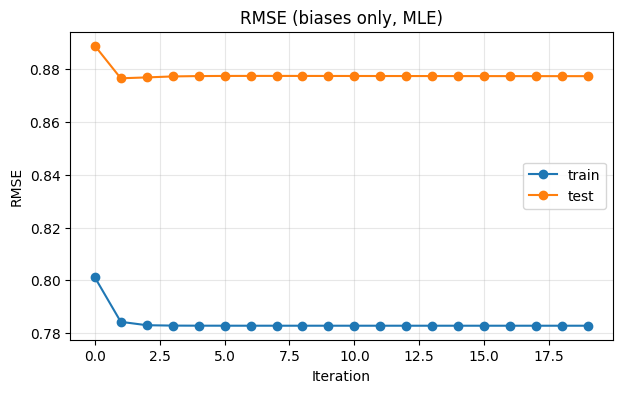

RMSE train : 0.7828282565200791
RMSE test  : 0.877357232029273


In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(rmse_by_train, marker="o", label="train")
plt.plot(rmse_by_test,  marker="o", label="test")
plt.xlabel("Iteration")
plt.ylabel("RMSE")
plt.title("RMSE (biases only, MLE)")
plt.ticklabel_format(useOffset=False, axis="y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("RMSE train :", rmse_by_train[-1])
print("RMSE test  :", rmse_by_test[-1])

## Practical 3 : user and item factors (latent trait vectors or matrices U and V)

In [ ]:

k = 10
llambda = 1.0
gamma   = 0.1          # même valeur que la Practical 2
tau     = 10.0
itera   = 20

n_user = len(index_to_user)          # définis AVANT d'être utilisés
n_item = len(index_to_item)

n_ratings = sum(len(l) for l in data_by_user_train)
mu = sum(float(r) for l in data_by_user_train for _, r in l) / n_ratings

rng = np.random.default_rng(0)
user_biases_3 = np.zeros(n_user)
item_biases_3 = np.zeros(n_item)
U = 0.1 * rng.standard_normal((n_user, k))
V = 0.1 * rng.standard_normal((n_item, k))

for m in range(n_user):
  if len(data_by_user_train[m]) == 0:
    U[m] = 0.0
for n in range(n_item):
  if len(data_by_item_train[n]) == 0:
    V[n] = 0.0

losses_3, rmse3_by_train, rmse3_by_test = [], [], []
print("N train =", n_ratings, " mu =", round(mu, 4), " n_user =", n_user, " n_item =", n_item)

N train = 90478  mu = 3.4997  n_user = 610  n_item = 9742


In [ ]:
def log_likelihood(data_by_user, U, V, user_biases, item_biases, mu, llambda):
  sse, N = 0.0, 0
  for m in range(len(data_by_user)):
    for n, r in data_by_user[m]:
      err = float(r) - (mu + U[m] @ V[n] + user_biases[m] + item_biases[n])
      sse += err ** 2
      N += 1
  return -(llambda / 2) * sse + (N / 2) * np.log(llambda / (2 * np.pi))

def log_prior_biases(user_biases, item_biases, gamma):
  n_b = len(user_biases) + len(item_biases)
  return ((n_b / 2) * np.log(gamma / (2 * np.pi))
          - (gamma / 2) * (np.sum(user_biases ** 2) + np.sum(item_biases ** 2)))

def log_prior_factors(U, V, tau):
  k = U.shape[1]
  n_f = U.shape[0] + V.shape[0]
  return ((n_f * k / 2) * np.log(tau / (2 * np.pi))
          - (tau / 2) * (np.sum(U ** 2) + np.sum(V ** 2)))

def total_loss(data_by_user, U, V, user_biases, item_biases, mu, llambda, gamma, tau):
  return -(log_likelihood(data_by_user, U, V, user_biases, item_biases, mu, llambda)
           + log_prior_biases(user_biases, item_biases, gamma)
           + log_prior_factors(U, V, tau))

def rmse_3(n_user, data_by_user, U, V, user_biases, item_biases, mu):
  se, N = 0.0, 0
  for m in range(n_user):
    for n, r in data_by_user[m]:
      err = float(r) - (mu + U[m] @ V[n] + user_biases[m] + item_biases[n])
      se += err ** 2
      N += 1
  return np.sqrt(se / N)

In [ ]:
for it in range(itera):
  for m in range(n_user):
    s, c = 0.0, 0
    for n, r in data_by_user_train[m]:
      s += llambda * (float(r) - mu - item_biases_3[n] - U[m] @ V[n])
      c += 1
    if c > 0:
      user_biases_3[m] = s / ((llambda * c) + gamma)

  for n in range(n_item):
    s, c = 0.0, 0
    for m, r in data_by_item_train[n]:
      s += llambda * (float(r) - mu - user_biases_3[m] - U[m] @ V[n])
      c += 1
    if c > 0:
      item_biases_3[n] = s / ((llambda * c) + gamma)

  for m in range(n_user):
    if len(data_by_user_train[m]) == 0:
      continue
    A = tau * np.eye(k)
    b = np.zeros(k)
    for n, r in data_by_user_train[m]:
      A += llambda * np.outer(V[n], V[n])
      b += llambda * V[n] * (float(r) - mu - user_biases_3[m] - item_biases_3[n])
    U[m] = np.linalg.solve(A, b)

  for n in range(n_item):
    if len(data_by_item_train[n]) == 0:
      continue
    A = tau * np.eye(k)
    b = np.zeros(k)
    for m, r in data_by_item_train[n]:
      A += llambda * np.outer(U[m], U[m])
      b += llambda * U[m] * (float(r) - mu - user_biases_3[m] - item_biases_3[n])
    V[n] = np.linalg.solve(A, b)

  losses_3.append(total_loss(data_by_user_train, U, V, user_biases_3, item_biases_3, mu, llambda, gamma, tau))
  rmse3_by_train.append(rmse_3(n_user, data_by_user_train, U, V, user_biases_3, item_biases_3, mu))
  rmse3_by_test.append(rmse_3(n_user, data_by_user_test, U, V, user_biases_3, item_biases_3, mu))  # paramètres figés

print("loss monotone :", bool(np.all(np.diff(losses_3) <= 1e-9)))
print(f"RMSE final  train {rmse3_by_train[-1]:.4f}   test {rmse3_by_test[-1]:.4f}")
print("changement relatif de la loss à la dernière itération :",
      abs(losses_3[-1] - losses_3[-2]) / losses_3[-1])

loss monotone : True
RMSE final  train 0.6272   test 0.8689
changement relatif de la loss à la dernière itération : 4.321418184628408e-05


In [ ]:
print(losses_3)

[np.float64(109587.17336735052), np.float64(106456.39957393002), np.float64(105233.24556588774), np.float64(104897.8153072813), np.float64(104752.76218791443), np.float64(104674.95779637911), np.float64(104626.25523756543), np.float64(104592.22727834123), np.float64(104566.6520720312), np.float64(104546.43144177298), np.float64(104529.83815191133), np.float64(104515.84562154008), np.float64(104503.82271162259), np.float64(104493.37110148523), np.float64(104484.23240609851), np.float64(104476.23303484458), np.float64(104469.24872688338), np.float64(104463.17980889755), np.float64(104457.93458956349), np.float64(104453.42072044601)]


In [ ]:
print(rmse3_by_train)

[np.float64(0.7907281933592406), np.float64(0.7102283675895904), np.float64(0.6615899912889722), np.float64(0.6460155180722912), np.float64(0.639484870501922), np.float64(0.6361059466408927), np.float64(0.6340540196048624), np.float64(0.6326501444760652), np.float64(0.6316098211285811), np.float64(0.6307966425147962), np.float64(0.6301366249017739), np.float64(0.6295862536179756), np.float64(0.62911871503864), np.float64(0.6287168336816402), np.float64(0.6283690952165744), np.float64(0.628067388856969), np.float64(0.6278056958249898), np.float64(0.6275792474857917), np.float64(0.6273839416377672), np.float64(0.6272159737326543)]


In [ ]:
print(rmse3_by_test)

[np.float64(0.8886121468754536), np.float64(0.8728971742169728), np.float64(0.8737134464237516), np.float64(0.8724450881703236), np.float64(0.8706921160092483), np.float64(0.8692981961668256), np.float64(0.8683272870537907), np.float64(0.8676792845710211), np.float64(0.8672596223726358), np.float64(0.8670070956880838), np.float64(0.8668868104492153), np.float64(0.8668779344442412), np.float64(0.866964719065952), np.float64(0.8671317970408892), np.float64(0.8673626406399385), np.float64(0.8676398613435311), np.float64(0.8679463347382187), np.float64(0.868266485812454), np.float64(0.8685873297519084), np.float64(0.8688990488552123)]


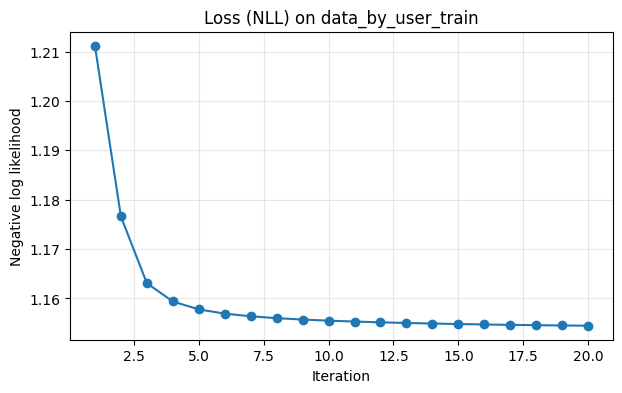

In [ ]:
n_ratings = sum(len(l) for l in data_by_user_train)
plt.figure(figsize = (7, 4))
plt.plot(range(1, n_iter + 1), np.array(losses_3) / n_ratings, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Negative log likelihood")
plt.title("Loss (NLL) on data_by_user_train")
plt.grid(alpha=0.3)
plt.show()

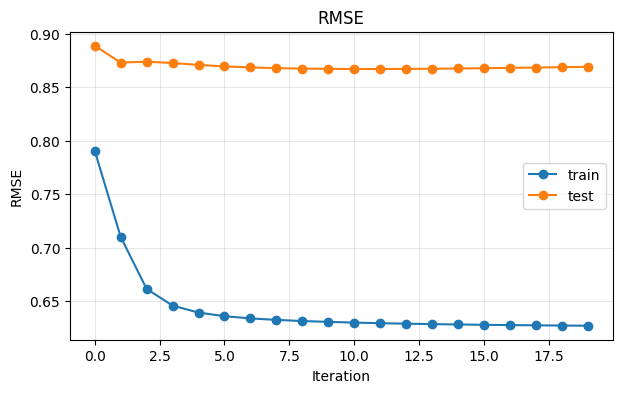

RMSE train : 0.6272159737326543
RMSE test  : 0.8688990488552123


In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(rmse3_by_train, marker="o", label="train")
plt.plot(rmse3_by_test,  marker="o", label="test")
plt.xlabel("Iteration")
plt.ylabel("RMSE")
plt.title("RMSE")
plt.ticklabel_format(useOffset=False, axis="y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("RMSE train :", rmse3_by_train[-1])
print("RMSE test  :", rmse3_by_test[-1])

## Practical 4

In [ ]:
movies_file4 = '/content/drive/MyDrive/ml-25m/movies.csv'
ratings_file4 = '/content/drive/MyDrive/ml-25m/ratings.csv'
tags_file4 = '/content/drive/MyDrive/ml-25m/tags.csv'

In [ ]:
user_to_index = {}
index_to_user = []

item_to_index = {}
index_to_item = []

data_by_user = []
data_by_item = []

In [ ]:
import csv

with open(ratings_file4, "r", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        u = row["userId"]
        if u not in user_to_index:
            user_to_index[u] = len(index_to_user)
            index_to_user.append(u)

# Films : tout le catalogue de movies.csv
with open(movies_file4, "r", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        m = row["movieId"]
        if m not in item_to_index:
            item_to_index[m] = len(index_to_item)
            index_to_item.append(m)

In [ ]:
def build_data(file_path, index_to_item, index_to_user, user_to_index, item_to_index):
    """Une seule lecture. Les deux listes sont alignées sur les indices,
    quel que soit l'ordre des lignes ; un utilisateur sans note a une liste vide."""
    data_by_user = [[] for _ in range(len(index_to_user))]
    data_by_item = [[] for _ in range(len(index_to_item))]
    with open(file_path, "r", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            u = user_to_index[row["userId"]]
            i = item_to_index[row["movieId"]]
            r = float(row["rating"])              # converti une seule fois
            data_by_user[u].append((i, r))
            data_by_item[i].append((u, r))
    return data_by_user, data_by_item


data_by_user, data_by_item = build_data(ratings_file4, index_to_item, index_to_user, user_to_index, item_to_index)


Users : n=162541, min=20, max=32202, moyenne=153.8, médiane=71


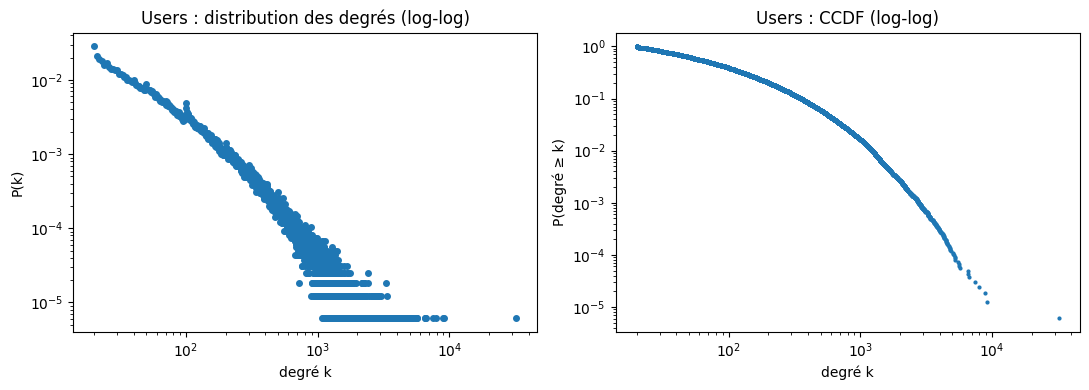

Films : n=59047, min=1, max=81491, moyenne=423.4, médiane=6


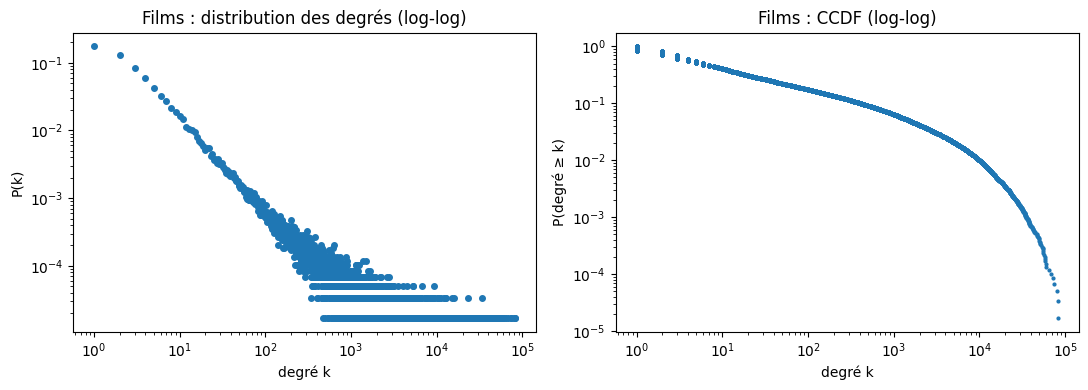

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

user_degrees = [len(l) for l in data_by_user]
item_degrees = [len(l) for l in data_by_item]

def plot_degrees(degrees, name):
    degrees = np.array([d for d in degrees if d > 0])   # log(0) impossible
    n = len(degrees)

    # distribution : proportion de noeuds pour chaque degré
    counts = Counter(degrees)
    x = np.array(sorted(counts))
    p = np.array([counts[k] for k in x]) / n

    # CCDF : proportion de noeuds de degré >= k
    d_sorted = np.sort(degrees)
    ccdf = 1 - np.arange(n) / n

    print(f"{name} : n={n}, min={degrees.min()}, max={degrees.max()}, "
          f"moyenne={degrees.mean():.1f}, médiane={np.median(degrees):.0f}")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].loglog(x, p, "o", markersize=4)
    axes[0].set_title(f"{name} : distribution des degrés (log-log)")
    axes[0].set_xlabel("degré k")
    axes[0].set_ylabel("P(k)")

    axes[1].loglog(d_sorted, ccdf, ".", markersize=4)
    axes[1].set_title(f"{name} : CCDF (log-log)")
    axes[1].set_xlabel("degré k")
    axes[1].set_ylabel("P(degré ≥ k)")

    plt.tight_layout()
    plt.show()

plot_degrees(user_degrees, "Users")
plot_degrees(item_degrees, "Films")


## Split data

In [ ]:

import os
import csv
import random

random.seed(42)

folder = os.path.dirname(ratings_file4)
train_file = os.path.join(folder, "4train_ratings_90.csv")
test_file = os.path.join(folder, "4test_ratings_10.csv")

n_train = 0
n_test = 0
previous_user_id = None
user_rows = []

with open(ratings_file4, "r", encoding="utf-8", newline="") as fin, \
     open(train_file, "w", encoding="utf-8", newline="") as ftrain, \
     open(test_file, "w", encoding="utf-8", newline="") as ftest:

    reader = csv.DictReader(fin)
    fieldnames = reader.fieldnames

    train_writer = csv.DictWriter(ftrain, fieldnames=fieldnames)
    test_writer = csv.DictWriter(ftest, fieldnames=fieldnames)

    train_writer.writeheader()
    test_writer.writeheader()

    def save_user(rows):
        global_dummy = None
        random.shuffle(rows)
        cut = int(0.9 * len(rows))

        train_writer.writerows(rows[:cut])
        test_writer.writerows(rows[cut:])

        return cut, len(rows) - cut

    for row in reader:
        user_id = row["userId"]

        if previous_user_id is not None and user_id != previous_user_id:
            # The file must be grouped by userId.
            a, b = save_user(user_rows)
            n_train += a
            n_test += b
            user_rows = []

        user_rows.append(row)
        previous_user_id = user_id

    # Save the last user
    if user_rows:
        a, b = save_user(user_rows)
        n_train += a
        n_test += b

print("ratings train :", n_train)
print("ratings test  :", n_test)
print("total         :", n_train + n_test)
print("Train file:", train_file)
print("Test file:", test_file)

ratings train : 22426477
ratings test  : 2573618
total         : 25000095
Train file: /content/drive/MyDrive/ml-25m/4train_ratings_90.csv
Test file: /content/drive/MyDrive/ml-25m/4test_ratings_10.csv


In [ ]:
def build_data(file_path):
    """Une seule lecture. Les deux listes sont alignées sur les indices,
    quel que soit l'ordre des lignes ; un utilisateur sans note a une liste vide."""
    data_by_user = [[] for _ in range(len(index_to_user))]
    data_by_item = [[] for _ in range(len(index_to_item))]
    with open(file_path, "r", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            u = user_to_index[row["userId"]]
            i = item_to_index[row["movieId"]]
            r = float(row["rating"])
            data_by_user[u].append((i, r))
            data_by_item[i].append((u, r))
    return data_by_user, data_by_item


data_by_user_train, data_by_item_train = build_data(train_file)
data_by_user_test,  data_by_item_test  = build_data(test_file)